In [1]:
import numpy as np
import pandas as pd

y_true = np.array([1, 1, 1, 1, 0, 1, 0, 0, 1, 1])
y_pred = np.array([1, 0, 1, 0, 0, 1, 1, 0, 1, 1])

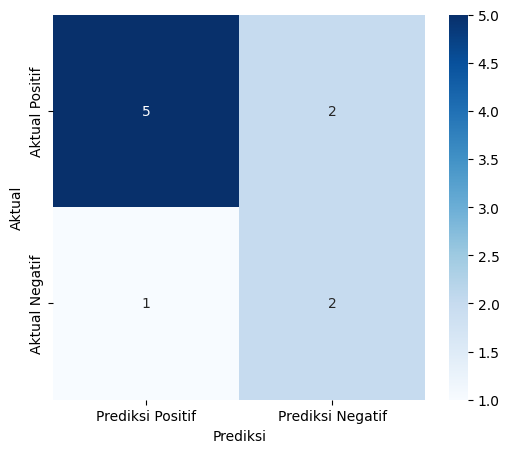

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix

conf_matrix = confusion_matrix(y_true, y_pred)

cm = pd.DataFrame({
    "Prediksi Positif": [conf_matrix[1][1], conf_matrix[0][1]], # TP, FP
    "Prediksi Negatif": [conf_matrix[1][0], conf_matrix[0][0]]  # FN, TN
}, index=["Aktual Positif", "Aktual Negatif"])

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, cmap="Blues")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()

In [3]:
count_0 = np.sum(y_true == 0)
count_1 = np.sum(y_true == 1)

print(f"Jumlah kelas 0 (Negatif): {count_0}")
print(f"Jumlah kelas 1 (Positif): {count_1}")

Jumlah kelas 0 (Negatif): 3
Jumlah kelas 1 (Positif): 7


In [4]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_true, y_pred)
print(f"Akurasi: {accuracy:.2f}")

Akurasi: 0.70


In [5]:
from sklearn.metrics import precision_score

precision = precision_score(y_true, y_pred)
print(f"Precision: {precision:.2f}")

Precision: 0.83


In [6]:
from sklearn.metrics import recall_score

recall = recall_score(y_true, y_pred)
print(f"Recall: {recall:.2f}")

Recall: 0.71


In [7]:
from sklearn.metrics import f1_score

f1 = f1_score(y_true, y_pred)
print(f"F1-Score: {f1:.3f}")

F1-Score: 0.769


In [8]:
from sklearn.metrics import roc_curve

fpr, tpr, threshold = roc_curve(y_true, y_pred)

df_roc = pd.DataFrame({
    "Threshold": threshold,
    "TPR (True Positive Rate)": tpr,
    "FPR (False Positive Rate)": fpr
})

df_roc


,Threshold,TPR (True Positive Rate),FPR (False Positive Rate)
0,inf,0.000000,0.000000
1,1.0,0.714286,0.333333
2,0.0,1.000000,1.000000


In [9]:
optimal_index = np.argmax(tpr - fpr)
optimal_threshold = threshold[optimal_index]

print(f"Optimal Threshold: {optimal_threshold}")

Optimal Threshold: 1.0


In [10]:
from sklearn.metrics import auc

roc_auc = auc(fpr, tpr)
print(roc_auc)

0.6904761904761906


In [11]:
from sklearn.metrics import roc_auc_score

score = roc_auc_score(y_true, y_pred)
print(roc_auc)

0.6904761904761906


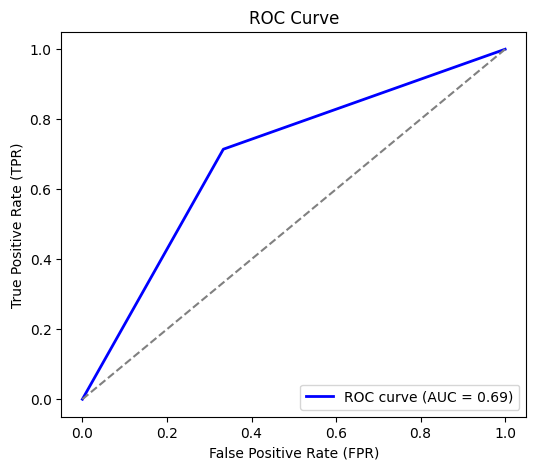

In [12]:
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--') 
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.show()